# GSN reflectivity with ISEM

Each point uses the public ISEM route and reads the GSN asymptotic amplitudes from the returned GSNRadialFunction.


In [1]:
using GeneralizedSasakiNakamura
using Plots, LaTeXStrings


In [2]:
function reflectivity_curve(s, l, m, a, omegas)
    return [begin
        Xin = GSN_radial(s, l, m, a, omega, IN; method = "ISEM")
        Xin.reflection_amplitude / Xin.incidence_amplitude
    end for omega in omegas]
end

s_values = -2:2
l = 2
m = 2
omegas = collect(range(0.02, 2.0; length = 100))

# Warm up once before the frequency sweeps.
GSN_radial(-2, l, m, 0.0, first(omegas), IN; method = "ISEM")


GSNRadialFunction(
    mode = Mode(s = -2, l = 2, m = 2, a = 0.0, omega = 0.02, lambda = 4.0),
    boundary_condition = IN,
    rsin = missing,
    rsout = missing,
    rsmp = 24.394449154672444,
    horizon_expansion_order = 80,
    infinity_expansion_order = 24,
    transmission_amplitude = 1.0 + 0.0im,
    incidence_amplitude = 20215.60919643624 - 107205.8708249867im,
    reflection_amplitude = 10915.430488063836 + 108547.7911833632im,
    normalization_convention = UNIT_GSN_TRANS,
    method = ISEM
)

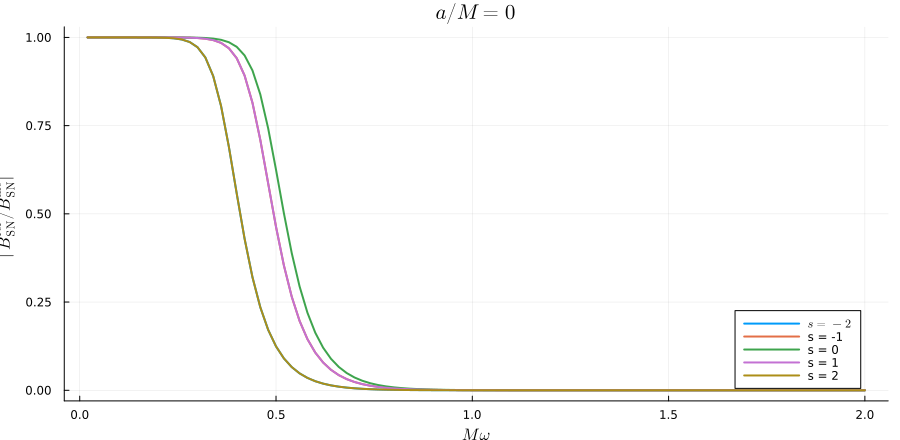

In [3]:
nonrotating = Dict(s => reflectivity_curve(s, l, m, 0.0, omegas) for s in s_values)

plot(omegas, abs.(nonrotating[-2]); linewidth = 2, label = L"s=-2")
for s in -1:2
    plot!(omegas, abs.(nonrotating[s]); linewidth = 2, label = "s = $s")
end
plot!(; xlabel = L"M\omega", ylabel = L"|B^{\mathrm{ref}}_{\mathrm{SN}}/B^{\mathrm{inc}}_{\mathrm{SN}}|",
    title = L"a/M=0", legend = :bottomright, size = (900, 440))


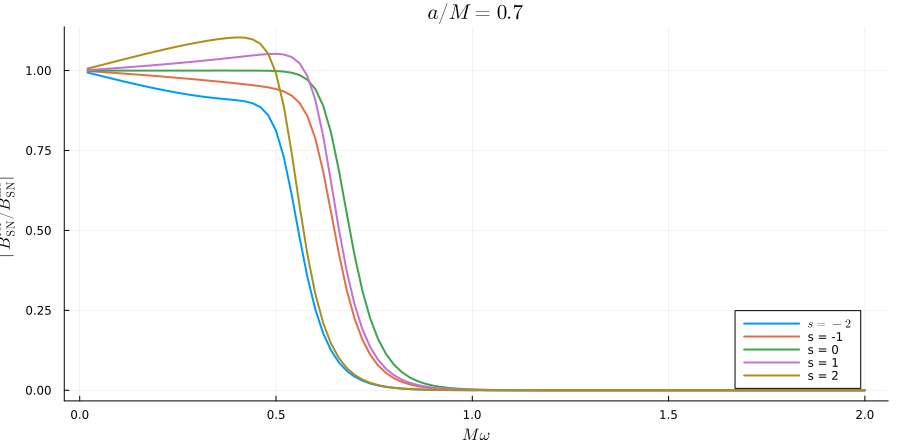

In [4]:
rotating = Dict(s => reflectivity_curve(s, l, m, 0.7, omegas) for s in s_values)

plot(omegas, abs.(rotating[-2]); linewidth = 2, label = L"s=-2")
for s in -1:2
    plot!(omegas, abs.(rotating[s]); linewidth = 2, label = "s = $s")
end
plot!(; xlabel = L"M\omega", ylabel = L"|B^{\mathrm{ref}}_{\mathrm{SN}}/B^{\mathrm{inc}}_{\mathrm{SN}}|",
    title = L"a/M=0.7", legend = :bottomright, size = (900, 440))
